## 1. Imports:

In [27]:
import pandas as pd
import numpy as np
import os
import joblib
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

## 2. Feature Engineering & Model Training:

### 2.1. Feature Engineering Function:

In [28]:
def build_features(history, candidate_question, topics):
    features = []

    total_history = len(history)

    global_success = (
        sum(h['correct'] for h in history) / total_history
        if total_history > 0 else 0
    )

    global_avg_time = (
        np.mean([h['time'] for h in history])
        if total_history > 0 else 0
    )


    for topic in topics:
        topic_data = [h for h in history if h['topic_id'] == topic]
        total = len(topic_data)

        easy_correct = sum(1 for h in topic_data if h['difficulty'] < 0.33 and h['correct'] == 1)
        easy_wrong   = sum(1 for h in topic_data if h['difficulty'] < 0.33 and h['correct'] == 0)

        med_correct = sum(1 for h in topic_data if 0.33 <= h['difficulty'] <= 0.66 and h['correct'] == 1)
        med_wrong   = sum(1 for h in topic_data if 0.33 <= h['difficulty'] <= 0.66 and h['correct'] == 0)

        hard_correct = sum(1 for h in topic_data if h['difficulty'] > 0.66 and h['correct'] == 1)
        hard_wrong   = sum(1 for h in topic_data if h['difficulty'] > 0.66 and h['correct'] == 0)

        success_rate = (
            sum(h['correct'] for h in topic_data) / total
            if total > 0 else 0
        )

        avg_time = (
            np.mean([h['time'] for h in topic_data])
            if total > 0 else 0
        )

        if total > 0:
            weights = np.linspace(1, 2, total)
            recent_weighted = np.average(
                [h['correct'] for h in topic_data],
                weights=weights
            )
        else:
            recent_weighted = 0

        avg_hints = (
            np.mean([h['hint_count'] for h in topic_data])
            if total > 0 else 0
        )

        avg_attempts = (
            np.mean([h['attempt_count'] for h in topic_data])
            if total > 0 else 0
        )

        features.extend([
            easy_correct, easy_wrong,
            med_correct, med_wrong,
            hard_correct, hard_wrong,
            success_rate, total, avg_time,
            recent_weighted,
            avg_hints, avg_attempts
        ])

    # Candidate question difficulty
    features.append(candidate_question['difficulty'])

    features.append(global_success * candidate_question['difficulty'])

    features.extend([
        global_success,
        global_avg_time,
        total_history
    ])

    # ONE-HOT topic encoding
    topic_vector = [0] * len(topics)
    topic_vector[candidate_question['topic_id']] = 1
    features.extend(topic_vector)

    return np.array(features)

### Purpose
This function converts a student's past answers (history) into a fixed-size feature vector.

For each topic, we compute:
- Number of correct/wrong answers (easy, medium, hard)
- Success rate
- Total questions seen
- Average response time

Additional features:
- Weighted success (favoring easy questions)
- Recent performance (last 3 answers)

We also include:
- Candidate question difficulty
- One-hot encoding of candidate topic

so the row that will be feed into our dataset instead of being our raw data it gonna be of this form:
[ Topic0_history | Topic1_history | Topic2_history | ... | Candidate_difficulty | Topic_one_hot ]

This transforms dynamic history into a fixed numerical input usable by ML models.

### 2.2. Build dataset:

In [29]:
train_df = pd.read_csv("../data/processed/train_data.csv")
test_df = pd.read_csv("../data/processed/test_data.csv")

In [30]:
topics = sorted(train_df['topic_id'].unique())

X = []
y = []
groups = []

for student_id, student_data in train_df.groupby('user_id'):
    student_data = student_data.sort_index()
    history = []

    for _, row in student_data.iterrows():
        candidate = {
            'difficulty': row['difficulty'],
            'topic_id': row['topic_id']
        }

        features = build_features(history, candidate, topics)

        X.append(features)
        y.append(row['correct'])
        groups.append(student_id)

        history.append({
            'topic_id': row['topic_id'],
            'difficulty': row['difficulty'],
            'correct': row['correct'],
            'time': row['response_time_norm'],
            'hint_count': row.get('hint_count', 0),        
            'attempt_count': row.get('attempt_count', 1)   
        })

X = np.array(X)
y = np.array(y)
groups = np.array(groups)

np.save("../outputs/X_train.npy", X)
np.save("../outputs/y_train.npy", y)

Iterate over each student:
- Build chronological history of the asked questions (Since no explicit timestamp was available, we assumed the dataset rows are ordered chronologically and sorted by index per student)

- Generate features for each question they answered (first we start with empty history then and build its features this will represent out first row, then we assume knowing answer of Q1 and build features -> row2 then assuming knowing Q1 and Q2 and build features -> row3 ..etc)

- Append features (X), target (y), and student_id (groups).

the table that we will be feeding to our models assuming that we have only 3 topics will  look like this:
| Row | candidate question | Difficulty | Features (37 values)                               | Target |
|-----|-------------|------------|---------------------------------------------------|--------|
| 1   | Q1          | 0.2        | [0,0,0,0,0,0,0,0,0,0,0, 0,0,0,0,0,0,0,0,0,0,0, 0,0,0,0,0,0,0,0,0,0,0, 0.2, 1,0,0] | 1 |
| 2   | Q2          | 0.5        | [1,0,0,0,0,0,0,0,0,0,0, 0,1,0,0,0,0,0,0,0,0,0, 0,0,0,0,0,0,0,0,0,0,0, 0.5, 0,1,0] | 0 |
| 3   | Q3          | 0.7        | [1,0,1,0,0,0,0,0,0,0,0, 0,1,0,0,0,0,0,0,0,0,0, 0,0,0,0,0,0,0,0,0,0,0, 0.7, 1,0,0] | 1 |
| 4   | Q4          | 0.4        | [2,0,1,0,0,0,0,0,0,0,0, 0,1,0,0,0,0,0,0,0,0,0, 0,0,1,0,0,0,0,0,0,0,0, 0.4, 0,0,1] | 0 |

Save features and labels for later use (This avoids recomputing features every time)

the reason why we build our new dataset like this and this is the dataset that gonna be feed into our models not our raw dataset is in order to perform the adaptive learning and predict if student will answer this question correct or not based on what he had answered before and so that our models learns the patterns of solving the questions of the quiz by most students

### 2.3. Model Evaluation with cross validation:

In [31]:
gkf = GroupKFold(n_splits=5)

models = {
    "logistic": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight='balanced'))
    ]),
    
    "random_forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        random_state=42
    ),
    "naive_bayes": GaussianNB(),
    
    "decision_tree": DecisionTreeClassifier(max_depth=12)
}

cv_results = {}

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=gkf.split(X, y, groups))
    
    print(f"{name} CV Accuracy: {scores.mean():.4f}")
    cv_results[name] = scores.mean()

    model.fit(X, y)
    joblib.dump(model, f"../models/{name}_model.pkl")

logistic CV Accuracy: 0.6977
random_forest CV Accuracy: 0.7265
naive_bayes CV Accuracy: 0.6779
decision_tree CV Accuracy: 0.6926


### Purpose
We evaluate models using 5-fold cross-validation.

Important:
We use GroupKFold to ensure that:
- The same student never appears in both training and testing folds

Models tested:
- Logistic Regression
- Naive Bayes
- Decision Tree

We compute average accuracy across folds.

we used GroupKFold to make sure that students in the training sample doesn't appear in the test sample

### 2.4. Select best model & Train Committee Models:

In [32]:
best_model_name = max(cv_results, key=cv_results.get)
print("Best model:", best_model_name)

for i in range(5):
    students_unique = np.unique(groups)  
    sample_students = np.random.choice(students_unique, size=int(0.8*len(students_unique)), replace=True)

    idx = [i for i, g in enumerate(groups) if g in sample_students]

    if best_model_name == "logistic":
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=1000))
        ])
    elif best_model_name == "naive_bayes":
        model = GaussianNB()
    else:
        model = DecisionTreeClassifier(max_depth=12)

    model.fit(X[idx], y[idx])
    joblib.dump(model, f"../models/committee_model_{i}.pkl")

Best model: random_forest


### Purpose
We choose the model with highest cross-validation accuracy.

This model will be used for:
- Final predictions
- Query-by-Committee

We train 5 versions of the best model using bootstrap sampling.

Each model sees a slightly different dataset.

During the quiz:
- All models make predictions
- We measure disagreement (variance)
- We select the most informative question

This improves robustness and uncertainty estimation.

### 2.5. Learning Curve Analysis:

113
226
340
453
567
680
793
907
1020
1134


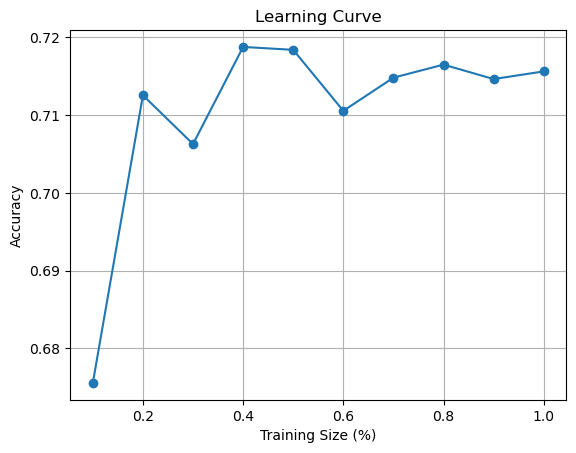

In [ ]:
# Define the fractions of training data
train_sizes = np.linspace(0.1, 1.0, 10)
accuracies = []

# Get unique students
unique_students = np.unique(groups)

for frac in train_sizes:
    # Number of students to include
    n_students = int(frac * len(unique_students))
    # print(n_students)
    
    # Randomly select students
    selected_students = np.random.choice(unique_students, n_students, replace=False)
    
    # Select all rows belonging to these students
    mask = np.isin(groups, selected_students)
    X_subset = X[mask]
    y_subset = y[mask]
    groups_subset = groups[mask]

    # Define the model pipeline
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000))
    ])

    # Evaluate with GroupKFold (by student)
    scores = cross_val_score(
        model, 
        X_subset, 
        y_subset, 
        cv=GroupKFold(5).split(X_subset, y_subset, groups_subset)
    )
    
    # Store the mean accuracy
    accuracies.append(scores.mean())

# Plot the learning curve
plt.figure()
plt.plot(train_sizes, accuracies, marker='o')
plt.xlabel("Training Size (%)")
plt.ylabel("Accuracy")
plt.title("Learning Curve")
plt.grid()
plt.savefig("../outputs/figures/learning_curve.png")
plt.show()

### 2.6. Model Comparison Table:

In [34]:
cv_table = pd.DataFrame({
    "Model": list(cv_results.keys()),
    "Accuracy": list(cv_results.values())
})

print(cv_table)

           Model  Accuracy
0       logistic  0.697652
1  random_forest  0.726473
2    naive_bayes  0.677868
3  decision_tree  0.692613
